### Block 1: Variable swapping
This block swaps two variables in one line using tuple unpacking.

In [28]:
x=1
y=2
x,y=y,x
print(x,y)

2 1


### Block 2: Word frequency sorting
This block counts how many times each word appears and sorts the results from most frequent to least frequent.

In [29]:
from collections import Counter
words=["apple", "banana", "apple", "orange", "banana", "apple"]
word_counts=Counter(words)
sorted_word_counts=sorted(word_counts.items(), key=lambda x: x[1], reverse=True)
print(sorted_word_counts)

[('apple', 3), ('banana', 2), ('orange', 1)]


### Block 3: List comprehensions
This block builds derived lists (even numbers, squares, and even squares) and demonstrates nested comprehensions for generating pairs.

In [30]:
even_numbers=[x for x in range(10) if x%2==0]
print(even_numbers)
squares=[x**2 for x in range(10)]
print(squares)
even_squares=[x**2 for x in even_numbers]
print(even_squares)
pairs=[(x,y) for x in range(5)
       for y in range(5)]
print(pairs)
pairs1=[(x,y) for x in range(5)
        for y in range(5) if y>x]
print(pairs1)


[0, 2, 4, 6, 8]
[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]
[0, 4, 16, 36, 64]
[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
[(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]


### Block 4: Generators
This block defines a finite generator and an infinite generator to show lazy value generation with `yield`.

In [31]:
def lazy_range(n):
    i=0
    while i<n:
        yield i
        i+=1
for x in lazy_range(5):
    print(x)
def natural_numbers():
    n = 1
    while True:
        yield n
        n += 1



0
1
2
3
4


### Block 5: Randomness
Playing around with Python's `random` module — generating random numbers, seeding it so results are repeatable, shuffling a list, and sampling with vs. without replacement.


In [32]:
import random

# seeding means "start the random number generator from this fixed point"
# so we get the same "random" numbers every time we run this cell
random.seed(10)

four_uniform_randoms = [random.random() for _ in range(4)]
print(four_uniform_randoms)

# re-seeding with the same number resets the sequence, so this
# gives us back the very first random number from before
random.seed(10)
print(random.random())
random.seed(10)
print(random.random())

random.seed(10)
print(random.randrange(10))     # random int from range(10), i.e. 0-9
print(random.randrange(3, 6))   # random int from range(3, 6), i.e. 3-5

# shuffle rearranges a list in place, returns None
up_to_ten = list(range(10))
random.shuffle(up_to_ten)
print(up_to_ten)

# choice picks one random element (with replacement if called again)
my_best_friend = random.choice(["Alice", "Bob", "Charlie"])
print(my_best_friend)

# sample picks n elements WITHOUT replacement, so no duplicates
lottery_numbers = range(60)
winning_numbers = random.sample(lottery_numbers, 6)
print(winning_numbers)

# to sample WITH replacement (duplicates allowed), just call choice repeatedly
four_with_replacement = [random.choice(range(10)) for _ in range(4)]
print(four_with_replacement)


[0.5714025946899135, 0.4288890546751146, 0.5780913011344704, 0.20609823213950174]
0.5714025946899135
0.5714025946899135
9
3
[9, 8, 4, 2, 5, 3, 1, 0, 7, 6]
Alice
[33, 31, 20, 4, 15, 47]
[5, 0, 6, 2]


### Block 6: Regular expressions
A quick tour of `re`: `match` only looks at the start of a string, `search` looks anywhere, `split` breaks a string apart on a pattern, and `sub` swaps matches out for something else.


In [33]:
import re

# quick cheat sheet for the four re functions I keep mixing up:
# match  -> only checks the START of the string
# search -> checks ANYWHERE in the string
# split  -> breaks the string apart wherever the pattern matches
# sub    -> replaces every match with something else
re_examples = [
    not re.match("a", "cat"),              # 'cat' doesn't START with 'a', so this is True
    re.search("a", "cat"),                 # but 'cat' does have an 'a' in it somewhere
    not re.search("c", "dog"),             # 'dog' has no 'c' anywhere
    3 == len(re.split("[ab]", "carbs")),   # split on 'a' or 'b' -> ['c', 'r', 's'] (3 pieces)
    "R-D-" == re.sub("[0-9]", "-", "R2D2") # swap every digit for a dash
]

print(all(re_examples))  # True means every assumption above held up
print(re.split("[ab]", "carbs"))
print(re.sub("[0-9]", "-", "R2D2"))


True
['c', 'r', 's']
R-D-


### Block 7: Functional tools
Messing around with `functools.partial` to lock in some of a function's arguments ahead of time, plus `map`/`filter` as the 'functional' alternative to list comprehensions.


In [34]:
from functools import partial

def exp(base, power):
    """base raised to the power'th power"""
    return base ** power

# partial "bakes in" an argument ahead of time and hands you back
# a smaller function that only needs whatever's left
two_to_the = partial(exp, 2)          # base is locked to 2
print(two_to_the(3))                  # same as exp(2, 3)

# you can also fix a KEYWORD argument instead of a positional one
square_of = partial(exp, power=2)     # power is locked to 2
print(square_of(5))                   # same as exp(5, power=2)

def double(x):
    return 2 * x

xs = [1, 2, 3, 4]

# these three lines all do the exact same thing, just different styles
twice_xs = [double(x) for x in xs]         # list comprehension
twice_xs_map = list(map(double, xs))       # map() version
print(twice_xs)
print(twice_xs_map)

# map also plays nicely with partial, since map just wants a function + iterable
list_doubler = partial(map, double)
print(list(list_doubler(xs)))

# map can take multiple lists too, and pairs them up like zip would
def multiply(x, y):
    return x * y

products = list(map(multiply, [1, 2, 3], [4, 5, 6]))
print(products)  # [1*4, 2*5, 3*6]

def is_even(x):
    return x % 2 == 0

# filter keeps only the elements where the function returns True
x_evens = [x for x in xs if is_even(x)]     # comprehension version
x_evens_filter = list(filter(is_even, xs))  # filter() version — same result
print(x_evens)
print(x_evens_filter)


8
25
[2, 4, 6, 8]
[2, 4, 6, 8]
[2, 4, 6, 8]
[4, 10, 18]
[2, 4]
[2, 4]


### Block 8: zip and argument unpacking
`zip` for pairing up two lists (it just stops at the shorter one), the 'unzip' trick with `zip(*pairs)`, and using `*` to unpack a list straight into a function call.


In [35]:
list1 = ['a', 'b', 'c']
list2 = [1, 2, 3]

# zip glues two lists together into pairs, one from each,
# and just stops early if one list runs out first
zipped = list(zip(list1, list2))
print(zipped)

# the "unzip" trick: * unpacks the list of pairs back into
# separate arguments, so zip can regroup them by position
pairs = [('a', 1), ('b', 2), ('c', 3)]
letters, numbers = zip(*pairs)
print(letters, numbers)

def add(a, b):
    return a + b

print(add(1, 2))
try:
    add([1, 2])   # this fails — add() wants TWO separate arguments, not one list
except TypeError:
    print("add expects two inputs")

# but * unpacks the list into two separate arguments as it's passed in,
# so this works exactly like add(1, 2)
print(add(*[1, 2]))


[('a', 1), ('b', 2), ('c', 3)]
('a', 'b', 'c') (1, 2, 3)
3
add expects two inputs
3


### Block 9: args and kwargs
Variadic functions with `*args`/`**kwargs`, unpacking a list and a dict into a call, and a `doubler` wrapper that breaks until it also accepts `*args, **kwargs` — good reminder of why that pattern exists.


In [36]:
def magic(*args, **kwargs):
    # args catches any extra POSITIONAL arguments as a tuple
    # kwargs catches any extra KEYWORD arguments as a dict
    print("unnamed args:", args)
    print("keyword args:", kwargs)

magic(1, 2, key="word", key2="word2")

def other_way_magic(x, y, z):
    return x + y + z

# the reverse trick: * and ** unpack a list/dict INTO a function call
x_y_list = [1, 2]
z_dict = {"z": 3}
print(other_way_magic(*x_y_list, **z_dict))   # same as other_way_magic(1, 2, z=3)

def doubler(f):
    """Takes a function and returns a new one that doubles its result."""
    def g(x):
        return 2 * f(x)
    return g

def f1(x):
    return x + 1

g = doubler(f1)
print(g(3))    # 2 * (3 + 1) = 8
print(g(-1))   # 2 * (-1 + 1) = 0

def f2(x, y):
    return x + y

g2 = doubler(f2)
try:
    g2(1, 2)   # breaks — g only ever defined room for ONE argument (x)
except TypeError:
    print("as defined, g only takes one argument")

# fix: let g accept anything and just forward it straight to f
def magic_doubler(f):
    def g(*args, **kwargs):
        return 2 * f(*args, **kwargs)
    return g

g3 = magic_doubler(f2)
print(g3(1, 2))   # now this works no matter how many args f actually needs


unnamed args: (1, 2)
keyword args: {'key': 'word', 'key2': 'word2'}
6
8
0
as defined, g only takes one argument
6


### Block 10: Type annotations
Adding type hints (`List`, `Optional`) to functions and variables. Doesn't change how the code runs, but makes it a lot more self-documenting and lets a tool like mypy catch mistakes early.


In [37]:
from typing import List, Optional

# type hints don't change how Python runs the code at all —
# they're just documentation that tools like mypy can double-check for you
def total(xs: List[float]) -> float:
    return sum(xs)

print(total([1.5, 2.5, 3.0]))

values: List[int] = []
# Optional[float] just means "a float, or maybe None" — handy for
# a running "best value so far" that starts out empty
best_so_far: Optional[float] = None

def greet(name: str, greeting: str = "Hello") -> str:
    return f"{greeting}, {name}!"

print(greet("Zarif"))
print(greet("Zarif", greeting="Hi"))


7.0
Hello, Zarif!
Hi, Zarif!


### Block 11: A first class (basic OOP)
A small `CountingClicker` class to get the basics of OOP down — `__init__`, `__repr__`, a couple methods — then a subclass that overrides `reset()` to see inheritance in action.


In [38]:
class CountingClicker:
    """A simple counter class to demonstrate basic OOP in Python."""

    def __init__(self, count: int = 0) -> None:
        # self.count is the object's own private piece of state
        self.count = count

    def __repr__(self) -> str:
        # this controls what gets printed when you just print(clicker)
        return f"CountingClicker(count={self.count})"

    def click(self, num_times: int = 1) -> None:
        """Click the counter some number of times."""
        self.count += num_times

    def read(self) -> int:
        return self.count

    def reset(self) -> None:
        self.count = 0


clicker = CountingClicker()
print(clicker)      # uses __repr__ above
clicker.click()
clicker.click(5)
print(clicker.read())
clicker.reset()
print(clicker.read())


# inheritance: NoResetClicker gets everything CountingClicker has for free,
# we're only overriding the one method we want to behave differently
class NoResetClicker(CountingClicker):
    """A subclass that overrides reset() to do nothing."""
    def reset(self) -> None:
        pass   # the reset button is disconnected, basically

clicker2 = NoResetClicker()
clicker2.click(3)
clicker2.reset()       # does nothing now
print(clicker2.read()) # still 3, proving the override worked


CountingClicker(count=0)
6
0
3


### Block 12: Line chart with matplotlib
First matplotlib chart — a line chart, good for showing how something changes over time.


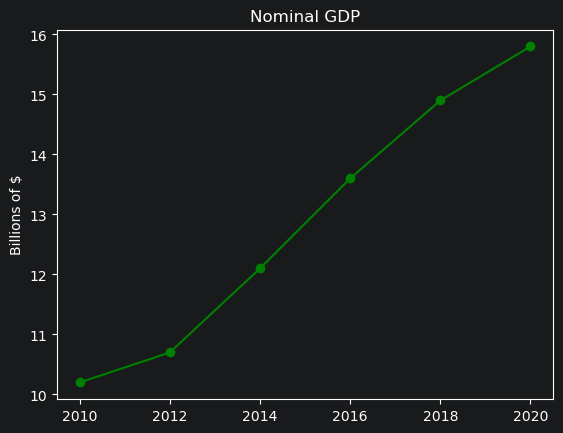

In [39]:
import matplotlib.pyplot as plt

years = [2010, 2012, 2014, 2016, 2018, 2020]
gdp = [10.2, 10.7, 12.1, 13.6, 14.9, 15.8]  # made-up trend, just for the chart

# plt.plot connects the dots with a line — good for showing change over time
plt.plot(years, gdp, color="green", marker="o", linestyle="solid")
plt.title("Nominal GDP")
plt.ylabel("Billions of $")
plt.show()


### Block 13: Bar chart with matplotlib
A bar chart for comparing separate categories, plus relabeling the x-axis ticks so it shows movie names instead of 0,1,2,3,4.


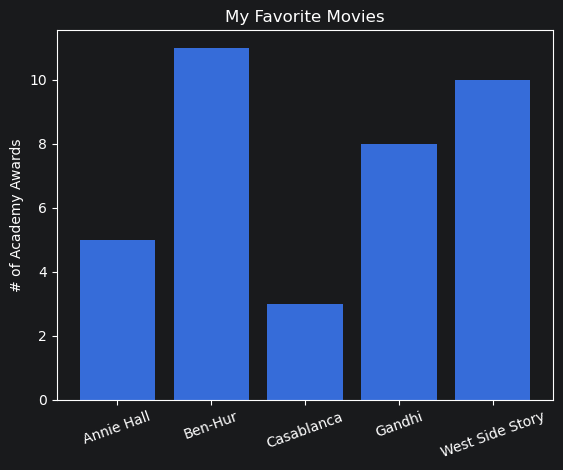

In [40]:
import matplotlib.pyplot as plt

movies = ["Annie Hall", "Ben-Hur", "Casablanca", "Gandhi", "West Side Story"]
num_oscars = [5, 11, 3, 8, 10]

# bar charts are the go-to when you're comparing separate, unrelated categories
plt.bar(range(len(movies)), num_oscars)
plt.title("My Favorite Movies")
plt.ylabel("# of Academy Awards")
# by default the x-axis would just show 0,1,2,3,4 — swap those for the movie names
plt.xticks(range(len(movies)), movies, rotation=20)
plt.show()


### Block 14: Scatter plot with matplotlib
A scatter plot to eyeball whether two variables move together, with each point labeled using `plt.annotate` so you can tell which dot is which.


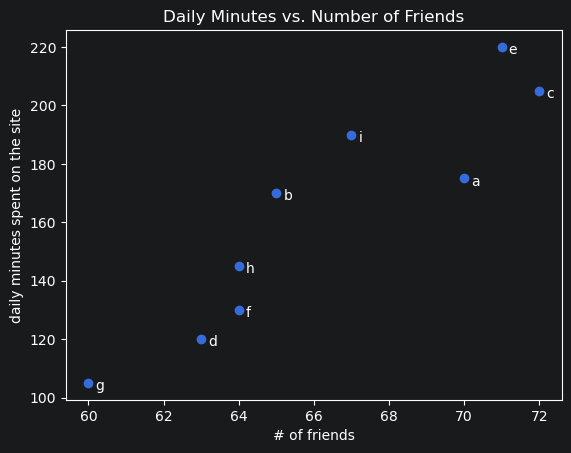

In [41]:
import matplotlib.pyplot as plt

friends = [70, 65, 72, 63, 71, 64, 60, 64, 67]
minutes = [175, 170, 205, 120, 220, 130, 105, 145, 190]
labels = ["a", "b", "c", "d", "e", "f", "g", "h", "i"]

# scatter plots are the move when you want to see if two variables
# seem related — here, more friends vs. more time spent on the site
plt.scatter(friends, minutes)

# label each point so we can tell which user is which dot
for label, friend_count, minute_count in zip(labels, friends, minutes):
    plt.annotate(label,
                 xy=(friend_count, minute_count),        # the point itself
                 xytext=(5, -5),                          # nudge the text a bit
                 textcoords="offset points")

plt.title("Daily Minutes vs. Number of Friends")
plt.xlabel("# of friends")
plt.ylabel("daily minutes spent on the site")
plt.show()


### Block 15: Vectors from scratch
Building vectors up from plain lists — no NumPy allowed, that's kind of the whole point of this book. Ends up with `add`, `subtract`, `vector_sum`, `scalar_multiply`, `vector_mean`, `dot`, `sum_of_squares`, `magnitude`, and `distance`.

The dot product and magnitude (Euclidean norm) of a vector, for reference:

$$
v \cdot w = \sum_{i=1}^{n} v_i w_i, \qquad \lVert v \rVert = \sqrt{v \cdot v}
$$


In [42]:
from typing import List
import math

# no numpy here on purpose — the whole point of this book is building
# things from scratch, so a "vector" is just a plain list of numbers
Vector = List[float]

def add(v: Vector, w: Vector) -> Vector:
    """Adds corresponding elements"""
    assert len(v) == len(w), "vectors must be the same length"
    return [v_i + w_i for v_i, w_i in zip(v, w)]

def subtract(v: Vector, w: Vector) -> Vector:
    """Subtracts corresponding elements"""
    assert len(v) == len(w), "vectors must be the same length"
    return [v_i - w_i for v_i, w_i in zip(v, w)]

def vector_sum(vectors: List[Vector]) -> Vector:
    """Sums all corresponding elements"""
    assert vectors, "no vectors provided!"
    num_elements = len(vectors[0])
    assert all(len(v) == num_elements for v in vectors), "different sizes!"
    # for each position i, add up that position across every vector
    return [sum(vector[i] for vector in vectors) for i in range(num_elements)]

def scalar_multiply(c: float, v: Vector) -> Vector:
    """Multiplies every element by c"""
    return [c * v_i for v_i in v]

def vector_mean(vectors: List[Vector]) -> Vector:
    """Computes the element-wise average"""
    n = len(vectors)
    return scalar_multiply(1 / n, vector_sum(vectors))

def dot(v: Vector, w: Vector) -> float:
    """Computes v_1 * w_1 + ... + v_n * w_n"""
    # this is the building block basically everything else in linear
    # algebra gets built out of — worth really internalizing
    assert len(v) == len(w), "vectors must be the same length"
    return sum(v_i * w_i for v_i, w_i in zip(v, w))

def sum_of_squares(v: Vector) -> float:
    """Returns v_1 * v_1 + ... + v_n * v_n"""
    return dot(v, v)   # dotting a vector with itself squares each element

def magnitude(v: Vector) -> float:
    """Returns the magnitude (length) of v"""
    return math.sqrt(sum_of_squares(v))   # just Pythagoras generalized to n dimensions

def distance(v: Vector, w: Vector) -> float:
    """Computes the distance between v and w"""
    return magnitude(subtract(v, w))   # "how far apart are these two points"


v = [1, 2, 3]
w = [4, 5, 6]

print(add(v, w))
print(subtract(v, w))
print(vector_sum([v, w, [1, 1, 1]]))
print(scalar_multiply(2, v))
print(vector_mean([v, w]))
print(dot(v, w))
print(sum_of_squares(v))
print(magnitude(v))
print(distance(v, w))


[5, 7, 9]
[-3, -3, -3]
[6, 8, 10]
[2, 4, 6]
[2.5, 3.5, 4.5]
32
14
3.7416573867739413
5.196152422706632


### Block 16: Matrices from scratch
Same idea as vectors, one level up — a matrix is just a list of rows. Writes `shape`, `get_row`, `get_column`, and `make_matrix`, then uses `make_matrix` to build an identity matrix and a little friendship adjacency matrix.


In [43]:
from typing import List, Tuple, Callable

# a matrix is just a list of rows, and each row is a list of numbers
Matrix = List[List[float]]

def shape(A: Matrix) -> Tuple[int, int]:
    """Returns (number of rows, number of columns) of A"""
    num_rows = len(A)
    num_cols = len(A[0]) if A else 0   # guard against an empty matrix
    return num_rows, num_cols

def get_row(A: Matrix, i: int) -> List[float]:
    """Returns the i-th row of A (as a list)"""
    return A[i]

def get_column(A: Matrix, j: int) -> List[float]:
    """Returns the j-th column of A (as a list)"""
    # rows are easy to grab (they're already lists), columns take
    # pulling out the j-th element from every single row
    return [A_i[j] for A_i in A]

def make_matrix(num_rows: int,
                 num_cols: int,
                 entry_fn: Callable[[int, int], float]) -> Matrix:
    """
    Returns a num_rows x num_cols matrix
    whose (i, j)-th entry is entry_fn(i, j)
    """
    # this is the neat trick — instead of writing separate functions
    # to build an identity matrix, a zero matrix, etc., you just pass
    # in whatever rule decides what goes in each cell
    return [[entry_fn(i, j) for j in range(num_cols)]
            for i in range(num_rows)]

def identity_matrix(n: int) -> Matrix:
    """Returns the n x n identity matrix"""
    return make_matrix(n, n, lambda i, j: 1 if i == j else 0)


A = [[1, 2, 3],
     [4, 5, 6]]

print(shape(A))
print(get_row(A, 1))
print(get_column(A, 2))
print(identity_matrix(5))

# a matrix can also represent a dataset: each row is one observation,
# each column is one feature. here, a friendship graph as an adjacency matrix
friendships = [(0, 1), (1, 2), (2, 3)]
n = 4
friend_matrix = make_matrix(n, n, lambda i, j: 1 if (i, j) in friendships or (j, i) in friendships else 0)
for row in friend_matrix:
    print(row)


(2, 3)
[4, 5, 6]
[3, 6]
[[1, 0, 0, 0, 0], [0, 1, 0, 0, 0], [0, 0, 1, 0, 0], [0, 0, 0, 1, 0], [0, 0, 0, 0, 1]]
[0, 1, 0, 0]
[1, 0, 1, 0]
[0, 1, 0, 1]
[0, 0, 1, 0]


### Block 17: Measures of central tendency
The basic "where's the center of this data" functions: `mean`, `median` (handling both even and odd length lists), `quantile`, and `mode`, run on a made-up "number of friends" dataset.

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i
$$


In [44]:
from typing import List
from collections import Counter

# a made-up "number of friends" dataset for 50 users
num_friends = [100, 49, 41, 40, 25, 21, 21, 19, 19, 18, 18, 16, 15, 15, 15,
               15, 14, 14, 13, 13, 13, 13, 12, 12, 11, 10, 10, 10, 10, 9,
               9, 9, 9, 9, 8, 8, 8, 6, 6, 5, 5, 4, 4, 4, 3, 3, 3, 3, 2, 2, 1]

def mean(xs: List[float]) -> float:
    return sum(xs) / len(xs)

def _median_odd(xs: List[float]) -> float:
    # odd length -> there's a single dead-center element after sorting
    return sorted(xs)[len(xs) // 2]

def _median_even(xs: List[float]) -> float:
    # even length -> average the two middle elements
    sorted_xs = sorted(xs)
    mid = len(xs) // 2
    return (sorted_xs[mid - 1] + sorted_xs[mid]) / 2

def median(v: List[float]) -> float:
    """Finds the 'middle-most' value of v"""
    return _median_even(v) if len(v) % 2 == 0 else _median_odd(v)

def quantile(xs: List[float], p: float) -> float:
    """Returns the pth-percentile value in x"""
    # e.g. p=0.1 -> the value 10% of the way up the sorted list
    p_index = int(p * len(xs))
    return sorted(xs)[p_index]

def mode(x: List[float]) -> List[float]:
    """Returns a list, since there might be more than one mode"""
    counts = Counter(x)
    max_count = max(counts.values())
    # there could be a tie for "most common", so return ALL of them
    return [x_i for x_i, count in counts.items() if count == max_count]


print(mean(num_friends))
print(median(num_friends))
print(median([1, 10, 2, 9, 5]))   # odd length, sanity check
print(median([1, 9, 2, 10]))      # even length, sanity check
print(quantile(num_friends, 0.10))
print(quantile(num_friends, 0.25))
print(quantile(num_friends, 0.75))
print(quantile(num_friends, 0.90))
print(mode(num_friends))


14.156862745098039
10
5
5.5
3
6
15
21
[9]


### Block 18: Dispersion
Now the "how spread out is this data" side: `data_range`, `variance` (built on `de_mean` and `sum_of_squares`), `standard_deviation`, and `interquartile_range`.

The (sample) variance and standard deviation:

$$
s^2 = \frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar{x})^2, \qquad s = \sqrt{s^2}
$$


In [45]:
from typing import List
import math

num_friends = [100, 49, 41, 40, 25, 21, 21, 19, 19, 18, 18, 16, 15, 15, 15,
               15, 14, 14, 13, 13, 13, 13, 12, 12, 11, 10, 10, 10, 10, 9,
               9, 9, 9, 9, 8, 8, 8, 6, 6, 5, 5, 4, 4, 4, 3, 3, 3, 3, 2, 2, 1]

def mean(xs: List[float]) -> float:
    return sum(xs) / len(xs)

def data_range(xs: List[float]) -> float:
    # the simplest possible measure of spread — biggest minus smallest
    return max(xs) - min(xs)

def de_mean(xs: List[float]) -> List[float]:
    """Translate xs by subtracting its mean (so the result has mean 0)"""
    # shifting everything to be "centered" around 0 makes the next
    # few formulas (variance, covariance) much cleaner to write
    x_bar = mean(xs)
    return [x - x_bar for x in xs]

def dot(v: List[float], w: List[float]) -> float:
    return sum(v_i * w_i for v_i, w_i in zip(v, w))

def sum_of_squares(v: List[float]) -> float:
    return dot(v, v)

def variance(xs: List[float]) -> float:
    """Almost the average squared deviation from the mean"""
    # "almost" because we divide by n-1, not n — this is Bessel's
    # correction, and it gives a less biased estimate for a sample
    assert len(xs) >= 2, "variance requires at least two elements"
    n = len(xs)
    deviations = de_mean(xs)
    return sum_of_squares(deviations) / (n - 1)

def standard_deviation(xs: List[float]) -> float:
    """The standard deviation is the square root of the variance"""
    # squaring in variance means the units get squared too (e.g. "friends^2"),
    # so taking the square root here brings it back to normal units
    return math.sqrt(variance(xs))

def interquartile_range(xs: List[float]) -> float:
    """Returns the difference between the 75%-ile and the 25%-ile"""
    # more resistant to outliers than range() since it ignores the extremes
    sorted_xs = sorted(xs)
    p75 = sorted_xs[int(0.75 * len(xs))]
    p25 = sorted_xs[int(0.25 * len(xs))]
    return p75 - p25


print(data_range(num_friends))
print(variance(num_friends))
print(standard_deviation(num_friends))
print(interquartile_range(num_friends))


99
243.65490196078434
15.609449124193471
9


### Block 19: Correlation
`covariance` and `correlation` between two variables — how strongly they move together, squeezed onto a -1 to 1 scale so it's actually interpretable.

$$
\operatorname{Cov}(x, y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})
$$

$$
\operatorname{Corr}(x, y) = \frac{\operatorname{Cov}(x, y)}{s_x \, s_y}
$$


In [46]:
from typing import List

num_friends = [100, 49, 41, 40, 25, 21, 21, 19, 19, 18, 18, 16, 15, 15, 15,
               15, 14, 14, 13, 13, 13, 13, 12, 12, 11, 10, 10, 10, 10, 9,
               9, 9, 9, 9, 8, 8, 8, 6, 6, 5, 5, 4, 4, 4, 3, 3, 3, 3, 2, 2, 1]

# made-up "minutes spent on the site" data, roughly tracking num_friends
# so the correlation actually shows something interesting
daily_minutes = [1 + 0.9 * x + ((-1) ** i) * (x % 5) for i, x in enumerate(num_friends)]

def mean(xs: List[float]) -> float:
    return sum(xs) / len(xs)

def de_mean(xs: List[float]) -> List[float]:
    x_bar = mean(xs)
    return [x - x_bar for x in xs]

def dot(v: List[float], w: List[float]) -> float:
    return sum(v_i * w_i for v_i, w_i in zip(v, w))

def sum_of_squares(v: List[float]) -> float:
    return dot(v, v)

def variance(xs: List[float]) -> float:
    n = len(xs)
    deviations = de_mean(xs)
    return sum_of_squares(deviations) / (n - 1)

def standard_deviation(xs: List[float]) -> float:
    return variance(xs) ** 0.5

def covariance(xs: List[float], ys: List[float]) -> float:
    """Measures how much xs and ys vary in tandem about their means"""
    # if xs and ys tend to be above their means together (or below
    # together), the products are mostly positive -> positive covariance
    assert len(xs) == len(ys), "xs and ys must have the same number of elements"
    return dot(de_mean(xs), de_mean(ys)) / (len(xs) - 1)

def correlation(xs: List[float], ys: List[float]) -> float:
    """Measures how much xs and ys vary together, on a scale of -1 to 1"""
    # covariance alone is hard to interpret since its size depends on
    # the units of xs and ys — dividing by both std devs fixes that
    stdev_x = standard_deviation(xs)
    stdev_y = standard_deviation(ys)
    if stdev_x > 0 and stdev_y > 0:
        return covariance(xs, ys) / (stdev_x * stdev_y)
    else:
        return 0  # if either variable never varies, "correlation" is meaningless -> call it 0


print(covariance(num_friends, daily_minutes))
print(correlation(num_friends, daily_minutes))


217.5313725490196
0.9825778762963349


### Block 20: Conditional probability (simulation)
The classic "two children" puzzle — instead of working it out on paper, just simulate 10,000 families with an `enum.Enum` for `Kid` and count. Compares P(both girls | older is a girl) against P(both girls | at least one is a girl), which surprisingly aren't the same number.

$$
P(E \mid F) = \frac{P(E, F)}{P(F)}
$$


In [47]:
import enum
import random

# an Enum is basically a fixed set of named options — cleaner than
# using raw strings like "boy"/"girl" that could get typo'd
class Kid(enum.Enum):
    BOY = 0
    GIRL = 1

def random_kid() -> Kid:
    return random.choice([Kid.BOY, Kid.GIRL])

random.seed(0)

both_girls = 0
older_girl = 0
either_girl = 0

# rather than working the probability out on paper, just simulate
# 10,000 families and count up how often each condition happens
for _ in range(10000):
    younger = random_kid()
    older = random_kid()
    if older == Kid.GIRL:
        older_girl += 1
    if older == Kid.GIRL and younger == Kid.GIRL:
        both_girls += 1
    if older == Kid.GIRL or younger == Kid.GIRL:
        either_girl += 1

# the classic surprising result: knowing the OLDER one is a girl gives
# 1/2, but knowing AT LEAST ONE is a girl (order unknown) gives 1/3
print("P(both | older):", both_girls / older_girl)     # should land near 1/2
print("P(both | either):", both_girls / either_girl)   # should land near 1/3


P(both | older): 0.5007089325501317
P(both | either): 0.3311897106109325


### Block 21: The uniform distribution
The simplest possible distribution — every value in [0, 1) is equally likely. PDF and CDF from scratch.

$$
f(x) = \begin{cases} 1 & 0 \le x < 1 \\ 0 & \text{otherwise} \end{cases}, \qquad F(x) = \begin{cases} 0 & x < 0 \\ x & 0 \le x < 1 \\ 1 & x \ge 1 \end{cases}
$$


In [48]:
def uniform_pdf(x: float) -> float:
    """The uniform distribution puts equal weight on every value in [0, 1)"""
    # flat 1 anywhere inside [0, 1), flat 0 everywhere else — no value
    # in that range is more "likely" than any other
    return 1 if 0 <= x < 1 else 0

def uniform_cdf(x: float) -> float:
    """Returns the probability that a uniform random variable is <= x"""
    if x < 0:
        return 0     # can't be <= a negative number, ever
    elif x < 1:
        return x     # probability grows in a straight line as x moves through [0, 1)
    else:
        return 1     # already guaranteed to be <= x once x >= 1


print(uniform_pdf(0.5), uniform_pdf(1.5))
print(uniform_cdf(-1), uniform_cdf(0.3), uniform_cdf(0.75), uniform_cdf(2))


1 0
0 0.3 0.75 1


### Block 22: The normal distribution
The bell curve. PDF and CDF from scratch using `math.erf`, plus an `inverse_normal_cdf` that binary-searches its way to an answer since there's no clean algebraic inverse.

The normal PDF:

$$
f(x \mid \mu, \sigma) = \frac{1}{\sqrt{2\pi}\,\sigma} \exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)
$$

Here's the twist that got me for a bit: the normal CDF has no simple closed form, but Python's `math.erf` (the Gauss error function) already does basically that integral — just centered and scaled differently — so `normal_cdf` is really just `erf` in disguise:

$$
\operatorname{erf}(x) = \frac{2}{\sqrt{\pi}} \int_{0}^{x} e^{-z^2}\,dz
$$

$$
F(x \mid \mu, \sigma) = \frac{1}{2}\left[1 + \operatorname{erf}\!\left(\frac{x-\mu}{\sigma\sqrt{2}}\right)\right]
$$

And the Z-score, which is the whole reason `inverse_normal_cdf` can cheat by solving the standard case first and then scaling back:

$$
Z = \frac{X - \mu}{\sigma}
$$

Solving for $X$:

$$
X = \mu + Z\sigma
$$


In [49]:
import math

SQRT_TWO_PI = math.sqrt(2 * math.pi)

def normal_pdf(x: float, mu: float = 0, sigma: float = 1) -> float:
    # the classic bell curve shape — mu shifts it left/right,
    # sigma controls how wide/narrow the bell is
    return (math.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (SQRT_TWO_PI * sigma))

def normal_cdf(x: float, mu: float = 0, sigma: float = 1) -> float:
    """The probability that a normal random variable is <= x"""
    # here's the twist: there's no simple closed-form way to integrate
    # the bell curve directly, but math.erf (the "error function") already
    # does almost exactly that integral, just centered/scaled differently.
    # so normal_cdf is really just erf wearing a normal-distribution costume
    return (1 + math.erf((x - mu) / math.sqrt(2) / sigma)) / 2

def inverse_normal_cdf(p: float,
                        mu: float = 0,
                        sigma: float = 1,
                        tolerance: float = 0.00001) -> float:
    """Find approximate inverse using binary search"""
    # if we're not on the standard normal, first solve the standard
    # case (mu=0, sigma=1) and then shift/scale the answer back —
    # this is exactly the Z-score relationship in reverse
    if mu != 0 or sigma != 1:
        return mu + sigma * inverse_normal_cdf(p, tolerance=tolerance)

    # normal_cdf has no algebraic inverse, so just binary search for
    # the z whose cdf is closest to p — cdf is monotonic, so this works
    low_z = -10.0
    hi_z = 10.0
    while hi_z - low_z > tolerance:
        mid_z = (low_z + hi_z) / 2
        mid_p = normal_cdf(mid_z)
        if mid_p < p:
            low_z = mid_z    # too low, search the upper half
        else:
            hi_z = mid_z     # too high (or just right), search the lower half
    return mid_z


print(normal_pdf(0))              # peak height of the standard normal curve
print(normal_cdf(0))              # exactly 0.5 — half the curve is below 0
print(normal_cdf(1.96))           # ~0.975, the famous "95% confidence" cutoff
print(inverse_normal_cdf(0.975))  # should come back out to ~1.96, round trip check


0.3989422804014327
0.5
0.9750021048517796
1.9599628448486328


### Block: Various Normal pdfs and cdfs (Figure 6-2)
This plots several normal distributions with different mu/sigma to show how the parameters shift and stretch the bell curve.

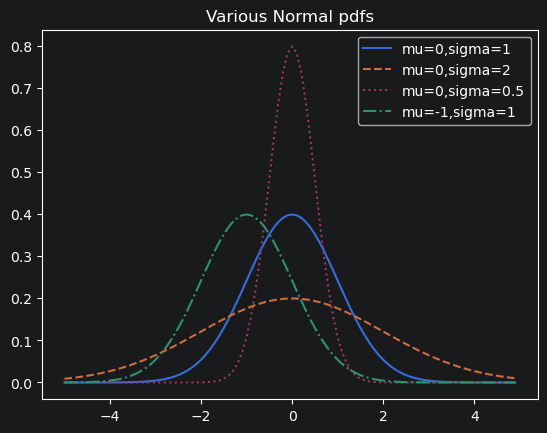

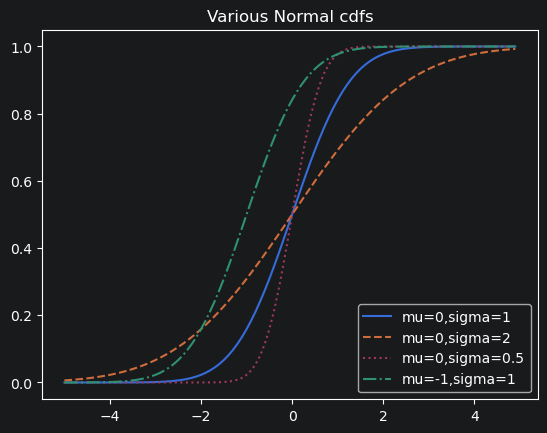

In [50]:
import math
import matplotlib.pyplot as plt

SQRT_TWO_PI = math.sqrt(2 * math.pi)

def normal_pdf(x: float, mu: float = 0, sigma: float = 1) -> float:
    return (math.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (SQRT_TWO_PI * sigma))

xs = [x / 10.0 for x in range(-50, 50)]
plt.plot(xs, [normal_pdf(x, sigma=1) for x in xs], '-', label='mu=0,sigma=1')
plt.plot(xs, [normal_pdf(x, sigma=2) for x in xs], '--', label='mu=0,sigma=2')
plt.plot(xs, [normal_pdf(x, sigma=0.5) for x in xs], ':', label='mu=0,sigma=0.5')
plt.plot(xs, [normal_pdf(x, mu=-1) for x in xs], '-.', label='mu=-1,sigma=1')
plt.legend()
plt.title("Various Normal pdfs")
plt.show()
#various normal cdf
def normal_cdf(x: float, mu: float = 0, sigma: float = 1) -> float:
    """The probability that a normal random variable is <= x"""
    # here's the twist: there's no simple closed-form way to integrate
    # the bell curve directly, but math.erf (the "error function") already
    # does almost exactly that integral, just centered/scaled differently.
    # so normal_cdf is really just erf wearing a normal-distribution costume
    return (1 + math.erf((x - mu) / math.sqrt(2) / sigma)) / 2
xs = [x / 10.0
for x in range(-50, 50)]
plt.plot(xs,[normal_cdf(x,sigma=1)
for x in xs],'-',label='mu=0,sigma=1')
plt.plot(xs,[normal_cdf(x,sigma=2)
for x in xs],'--',label='mu=0,sigma=2')
plt.plot(xs,[normal_cdf(x,sigma=0.5)
for x in xs],':',label='mu=0,sigma=0.5')
plt.plot(xs,[normal_cdf(x,mu=-1)
for x in xs],'-.',label='mu=-1,sigma=1')
plt.legend(loc=4) # bottom right
plt.title("Various Normal cdfs")
plt.show()


### Block 23: The Central Limit Theorem
The payoff block — simulate a Binomial(n, p) a bunch of times, plot its histogram, then lay the matching normal curve right on top. Once n gets big enough the two are basically indistinguishable, which is the Central Limit Theorem showing up in real life.

A Binomial(n, p) is just the sum of n independent Bernoulli(p) trials, and for large n it's well approximated by a normal with matching mean and variance:

$$
X \sim \operatorname{Binomial}(n, p) \;\approx\; \mathcal{N}\bigl(\mu, \sigma^2\bigr), \qquad \mu = np, \quad \sigma = \sqrt{np(1-p)}
$$


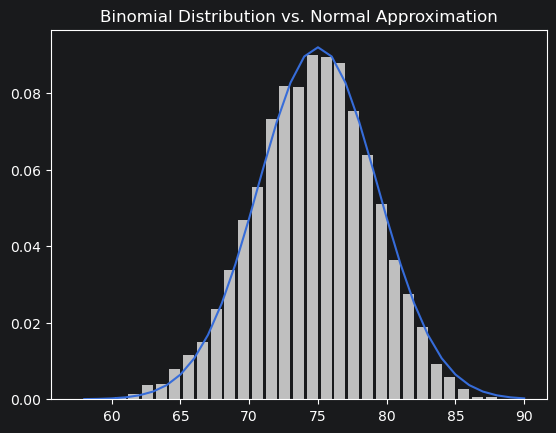

In [51]:
import random
import matplotlib.pyplot as plt
from collections import Counter
def normal_cdf(x: float, mu: float = 0, sigma: float = 1) -> float:
    return (1 + math.erf((x - mu) / math.sqrt(2) / sigma)) / 2
def bernoulli_trial(p: float) -> int:
    """Returns 1 with probability p, 0 with probability 1-p"""
    return 1 if random.random() < p else 0

def binomial(n: int, p: float) -> int:
    """Returns the sum of n bernoulli(p) trials"""
    # e.g. n=100 coin flips, each with probability p of landing heads —
    # binomial(100, 0.5) is just "how many heads did we get"
    #basically calculating sum to apply CLT
    return sum(bernoulli_trial(p) for _ in range(n))
def make_hist(p: float, n: int, num_points: int) -> None:
    """Picks points from a Binomial(n, p) and plots their histogram"""
    data = [binomial(n, p) for _ in range(num_points)]

    # bar chart of the ACTUAL simulated binomial outcomes
    histogram = Counter(data)
    plt.bar([x - 0.4 for x in histogram.keys()],
            [v / num_points for v in histogram.values()],
            0.8,
            color="0.75")
    #calculating the mean of RV sum to plot normal dist
    mu = p * n
    #calculating the std of RV sum
    sigma = (n * p * (1 - p)) ** 0.5

    # line chart of the THEORETICAL normal curve with matching mean/variance
    import math
    SQRT_TWO_PI = math.sqrt(2 * math.pi)
    def normal_pdf(x, mu=0, sigma=1):
        return math.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (SQRT_TWO_PI * sigma)

    xs = range(min(data), max(data) + 1)
    #binomial is discrete so for normal approximation we use diffs of cdfs instead of direct pdf
    ys = [normal_cdf(i + 0.5, mu, sigma) - normal_cdf(i - 0.5, mu, sigma) for i in xs]
    plt.plot(xs, ys)
    plt.title("Binomial Distribution vs. Normal Approximation")
    plt.show()
random.seed(0)
# with n=100 and 10,000 samples, the bars should hug that smooth
# normal curve pretty closely — that's the Central Limit Theorem in action
make_hist(0.75, 100, 10000)


### BLOCK 24: HYPOTHESIS TESTING

This block builds the probability tools needed for hypothesis testing. The functions use the normal distribution to calculate probabilities, find cutoff values, and create a two-sided interval around the mean.

In [52]:
# Convert a binomial distribution into its matching normal distribution.
# The mean is the expected number of successes, and sigma measures the spread.
def normal_approximation_to_binomial(n, p):
    """Find the mean and standard deviation for Binomial(n, p)."""
    mu = p * n
    sigma = math.sqrt(p * (1 -p)*n)
    return mu, sigma


# The normal CDF gives the probability that a value is below a threshold.
# We can reuse normal_cdf directly because it already has the right behavior.
normal_probability_below = normal_cdf


# If a value is not below the threshold, it must be above it.
def normal_probability_above(lo, mu=0, sigma=1):
    return 1 - normal_cdf(lo, mu, sigma)


# The probability of being between lo and hi is:
# probability below hi minus probability below lo.
def normal_probability_between(lo, hi, mu=0, sigma=1):
    return normal_cdf(hi, mu, sigma) - normal_cdf(lo, mu, sigma)


# The probability outside the interval is the complement of the
# probability inside the interval.
def normal_probability_outside(lo, hi, mu=0, sigma=1):
    return 1 - normal_probability_between(lo, hi, mu, sigma)


def normal_upper_bound(probability, mu=0, sigma=1):
    """Find the cutoff where the probability below it equals probability."""
    return inverse_normal_cdf(probability, mu, sigma)


def normal_lower_bound(probability, mu=0, sigma=1):
    """Find the cutoff where the probability above it equals probability."""
    # inverse_normal_cdf expects the probability below the cutoff,
    # so convert P(Z >= z) into P(Z <= z).
    return inverse_normal_cdf(1 - probability, mu, sigma)


def normal_two_sided_bounds(probability, mu=0, sigma=1):
    """Return symmetric lower and upper bounds containing the given probability."""
    # The probability not included in the interval is split equally
    # between the lower and upper tails.
    tail_probability = (1 - probability) / 2

    # Find the upper cutoff by leaving tail_probability above it.
    upper_bound = normal_lower_bound(tail_probability, mu, sigma)

    # Find the lower cutoff by leaving tail_probability below it.
    lower_bound = normal_upper_bound(tail_probability, mu, sigma)

    return lower_bound, upper_bound
#if we flip coin 100 times
mu_0, sigma_0 = normal_approximation_to_binomial(1000, 0.5)
# testing with 5% significance level
normal_two_sided_bounds(0.95, mu_0, sigma_0) # (469, 531)
# 95% bounds based on assumption p is 0.5
lo, hi = normal_two_sided_bounds(0.95, mu_0, sigma_0)
# actual mu and sigma based on p = 0.55
mu_1, sigma_1 = normal_approximation_to_binomial(1000, 0.55)
# a type 2 error means we fail to reject the null hypothesis
# which will happen when X is still in our original interval
type_2_probability = normal_probability_between(lo, hi, mu_1, sigma_1)
power = 1 - type_2_probability # 0.887
#when null hypothesis is p<=.5 ( not biased towards heads)
hi = normal_upper_bound(0.95, mu_0, sigma_0)
# is 526 (< 531, since we need more probability in the upper tail)
type_2_probability = normal_probability_below(hi, mu_1, sigma_1)
power = 1 - type_2_probability
# 0.936
#two sided p value
def two_sided_p_value(x: float, mu: float = 0, sigma: float = 1) -> float:
    """
    How likely are we to see a value at least as extreme as x (in either
    direction) if our values are from an N(mu, sigma)?
    """
    if x >= mu:
    # x is greater than the mean, so the tail is everything greater than x
        return 2 * normal_probability_above(x, mu, sigma)
    else:
    # x is less than the mean, so the tail is everything less than x
        return 2 * normal_probability_below(x, mu, sigma)
#if we were to see 530 heads how likely are we to see 530 heads or more extreme (on the both side)
two_sided_p_value(531.5, mu_0, sigma_0)   # 0.0463
#for one sided test
upper_p_value = normal_probability_above
lower_p_value = normal_probability_below
upper_p_value(524.5, mu_0, sigma_0) # 0.061
#confidence interval of estimated probability of coin tosses using CLT and normal approximation
#if we get 525 heads out of 1000 tosses
p_hat = 525 / 1000
mu = p_hat
sigma = math.sqrt(p_hat * (1 - p_hat) / 1000)   # 0.0158
#using CLT
normal_two_sided_bounds(0.95, mu, sigma)  # [0.4940, 0.5560]
#for 340 heads
p_hat = 540 / 1000
mu = p_hat
sigma = math.sqrt(p_hat * (1 - p_hat) / 1000) # 0.0158
normal_two_sided_bounds(0.95, mu, sigma) # [0.5091, 0.5709]
#the .5 doesnt fall in the 95% confidence interval
#p-hacking - by setting 5% significance level 5% of the time you erroneously reject the null hypothesis if you’re setting out to find “significant” results,you usually can by testing enough so that it falls in that rejection region
from typing import List

def run_experiment() -> List[bool]:
    """Flips a fair coin 1000 times, True = heads, False = tails"""
    return [random.random() < 0.5 for _ in range(1000)]

def reject_fairness(experiment: List[bool]) -> bool:
    """Using the 5% significance levels"""
    num_heads = len([flip for flip in experiment if flip])
    return num_heads < 469 or num_heads > 531

random.seed(0)
experiments = [run_experiment() for _ in range(1000)]
num_rejections = len([experiment
                      for experiment in experiments
                      if reject_fairness(experiment)])

assert num_rejections == 46
print(num_rejections)

46


### BLOCK 25: A/B TEST
This block estimates the conversion rate and standard error for each variant, then compares them using a two-sample z-test. For each group, $p = n / N$ and $\sigma = \sqrt{p(1-p)/N}$, and the test statistic is
$$
z = \frac{p_B - p_A}{\sqrt{\sigma_A^2 + \sigma_B^2}}
$$
A small p-value tells us the observed difference is unlikely to be due to random noise. This is a common A/B testing setup for comparing conversion rates across two versions.


In [53]:
def estimated_parameters(N: int, n: int) -> Tuple[float, float]:
    p = n / N
    sigma = math.sqrt(p * (1 - p) / N)
    #in standard dev we devide by N because we are calculating all about n/N proportion var(n/N)=1/N^2 * var(n)
    return p, sigma
def a_b_test_statistic(N_A: int, n_A: int, N_B: int, n_B: int) -> float:
    p_A, sigma_A = estimated_parameters(N_A, n_A)
    p_B, sigma_B = estimated_parameters(N_B, n_B)
    return (p_B - p_A) / math.sqrt(sigma_A ** 2 + sigma_B ** 2)
z = a_b_test_statistic(1000, 200, 1000, 180)    # -1.14
#we should have used t distribution because the standard dev is estimated but the sample size is large so it doesnt matter that much we can use z-distribution(mu=0,sigma=1)
two_sided_p_value(z) #0.254>.05 so we accept H0 that the difference is zero
z = a_b_test_statistic(1000, 200, 1000, 150)
two_sided_p_value(z)# 0.003 <.05 so we reject the null hypothesis, the difference is significant



0.003189699706216853

### BLOCK 26:GRADIENT DESCENT

This block introduces gradient descent, a method for minimizing a function by moving in the direction that reduces it the fastest. The derivative tells us how quickly the function is changing at a point:

$$
f'(x) \approx \frac{f(x+h)-f(x)}{h}
$$

Then we update the value by stepping opposite the slope:

$$
x_{new} = x - \eta \cdot f'(x)
$$

Here, $\eta$ is the learning rate. Repeating this process moves us toward the minimum of the function, which is the core idea behind training machine learning models.


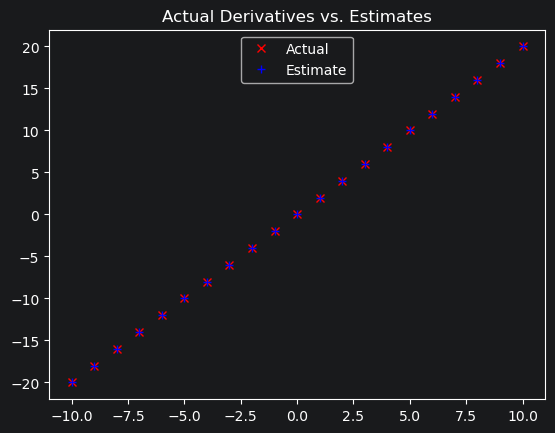

950 [2.3435788385574745e-08, 3.864847568515378e-08, 2.9993559741506895e-08]
951 [2.296707261786325e-08, 3.78755061714507e-08, 2.9393688546676756e-08]
952 [2.2507731165505985e-08, 3.7117996048021687e-08, 2.880581477574322e-08]
953 [2.2057576542195866e-08, 3.637563612706125e-08, 2.8229698480228355e-08]
954 [2.161642501135195e-08, 3.5648123404520025e-08, 2.7665104510623787e-08]
955 [2.118409651112491e-08, 3.4935160936429625e-08, 2.711180242041131e-08]
956 [2.0760414580902413e-08, 3.4236457717701035e-08, 2.6569566372003086e-08]
957 [2.0345206289284364e-08, 3.3551728563347016e-08, 2.6038175044563023e-08]
958 [1.9938302163498677e-08, 3.2880693992080073e-08, 2.551741154367176e-08]
959 [1.9539536120228703e-08, 3.222308011223847e-08, 2.5007063312798326e-08]
960 [1.9148745397824128e-08, 3.1578618509993705e-08, 2.450692204654236e-08]
961 [1.8765770489867645e-08, 3.094704613979383e-08, 2.4016783605611514e-08]
962 [1.8390455080070293e-08, 3.032810521699795e-08, 2.3536447933499285e-08]
963 [1.802264

In [56]:
import sys
import scratch
from importlib import reload
from typing import Callable
from typing import List, Tuple
Vector = List[float]
def difference_quotient(f: Callable[[float], float],
                        x: float,
                        h: float) -> float:
    return (f(x + h) - f(x)) / h #for small increase in x how does f(x) change
def square(x: float) -> float:
    return x * x
def derivative(x: float) -> float:
    return 2 * x  #derivative value of x^2
xs = range(-10, 11)
actuals = [derivative(x) for x in xs] #actual derivative
estimates = [difference_quotient(square, x, h=0.001) for x in xs] #estimates using limits
# plot to show they're basically the same
import matplotlib.pyplot as plt
plt.title("Actual Derivatives vs. Estimates")
plt.plot(xs, actuals, 'rx', label='Actual')
# red  x
plt.plot(xs, estimates, 'b+', label='Estimate')   # blue +
plt.legend(loc=9)
plt.show()
def partial_difference_quotient(f: Callable[[Vector], float],
                                v: Vector,
                                i: int,
                                h: float) -> float:
    """Returns the i-th partial difference quotient of f at v"""
    w=[v_j +(h if j==i else 0) # add h to just the ith element of v
       for j, v_j in enumerate(v)]
    return (f(w)-f(v)) / h
def estimate_gradient(f: Callable[[Vector], float],
                      v: Vector,
                      h: float = 0.0001):
    return [partial_difference_quotient(f, v, i, h)
            for i in range(len(v))] #returns[df/dx1,df/dx2,...df/dxn] where n is length of v

import random
from scratch.linear_algebra import distance, add, scalar_multiply

def gradient_step(v: Vector, gradient: Vector, step_size: float) -> Vector:
    """Moves `step_size` in the `gradient` direction from `v`"""
    assert len(v) == len(gradient)
    step = scalar_multiply(step_size, gradient)
    return add(v, step) #adding the step to the vector

def sum_of_squares_gradient(v: Vector) -> Vector:
    return [2 * v_i for v_i in v]     #gradient of [x1^2,x2^2,x3^2]=[2x1,2x2,2x3]

v=[random.uniform(-10, 10) for i in range(3)]    # start at a random point
for epoch in range(1000):
    grad = sum_of_squares_gradient(v)    # compute the gradient at v
    v = gradient_step(v, grad, -0.01)    # take a negative gradient step (if starting point is (-)ve the steps will be positive ,(-)ve for otherwise
    if epoch >= 950:  # print only the last 50 epochs to avoid clutter if you want to see all just remove condition
        print(epoch, v)

assert distance(v, [0, 0, 0]) < 0.001    # v should be close to 0
#gradient descent for linear regression
# x ranges from -50 to 49, y is always 20 * x + 5
inputs=[(x,20*x+5) for x in range(-50,50)]
def linear_gradient(x: float, y: float, theta: Vector) -> Vector:
    """Computes the gradient of the squared error cost function for linear regression"""
    slope, intercept = theta
    predicted = slope * x + intercept
    error = predicted - y
    squared_error = error ** 2
    # gradient of squared error with respect to slope and intercept
    return [2 * error * x, 2 * error]  # [d/dsquared_error/dslope, d/squared_error/d/intercept]
from scratch.linear_algebra import vector_mean
# Start with random values for slope and intercept
theta = [random.uniform(-1, 1), random.uniform(-1, 1)]
learning_rate = 0.001
for epoch in range(5000):
    # Compute the mean of the gradients
    grad = vector_mean([linear_gradient(x, y, theta)
    for x, y in inputs])
    # Take a step in that direction
    theta = gradient_step(theta, grad, -learning_rate)
    if epoch >= 4950:  # print only the last 50 epochs to avoid clutter if you want to see all just remove condition
        print(epoch, theta)
slope, intercept = theta
assert 19.9 < slope < 20.1,   "slope should be about 20"
assert 4.9 < intercept < 5.1, "intercept should be about 5"
